In [4]:
%%writefile tir_reader.py
def parse_value(text):
    text = text.strip()
    try:
        return float(text)
    except ValueError:
        return text.strip("'")


def load_tir(path):
    params = {}
    section = None

    with open(path) as f:
        for line in f:
            line = line.split("$")[0].strip()

            if line == "" or line.startswith("!"):
                continue

            if line.startswith("["):
                section = line.strip("[]")
                params[section] = {}
                continue

            key, value = line.split("=")
            params[section][key.strip()] = parse_value(value)

    return params

Writing tir_reader.py


In [5]:
from tir_reader import load_tir

tyre = load_tir("data/sample.tir")
print(tyre["LATERAL_COEFFICIENTS"]["PCY1"])

1.337


In [2]:
import os
print(os.getcwd())
print(os.listdir())

e:\Projects\Tire_modelling
['01_explore_tir.ipynb', '03_magic_formula.ipynb', 'data']


In [6]:
import numpy as np
from tir_reader import load_tir

tyre = load_tir("data/sample.tir")
lat = tyre["LATERAL_COEFFICIENTS"]
Fz0 = tyre["VERTICAL"]["FNOMIN"]

Fz = Fz0

Cy = lat["PCY1"]
mu_y = lat["PDY1"]
Dy = mu_y * Fz
Kya = lat["PKY1"] * Fz0 * np.sin(lat["PKY4"] * np.arctan(Fz / (lat["PKY2"] * Fz0)))
By = Kya / (Cy * Dy)
Ey = lat["PEY1"]

print("C =", Cy)
print("D =", Dy, "N")
print("Cornering stiffness =", Kya, "N/rad")
print("B =", By)
print("E =", Ey)

C = 1.337
D = 3514.0 N
Cornering stiffness = -53353.12739107985 N/rad
B = -11.356034860681188
E = -0.8057


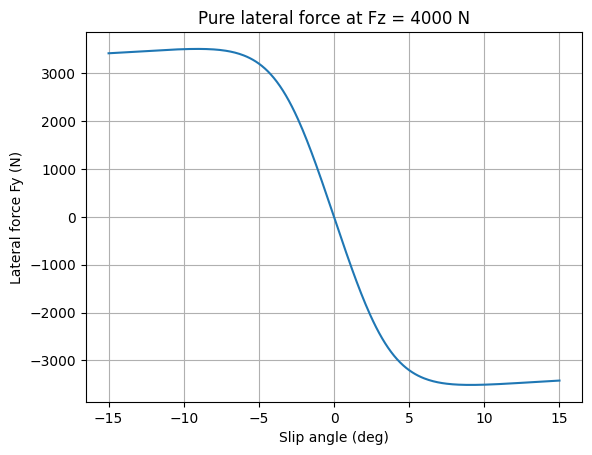

In [7]:
import matplotlib.pyplot as plt

def magic_formula(x, B, C, D, E):
    Bx = B * x
    return D * np.sin(C * np.arctan(Bx - E * (Bx - np.arctan(Bx))))

alpha_deg = np.linspace(-15, 15, 301)
alpha = np.radians(alpha_deg)

Fy = magic_formula(alpha, By, Cy, Dy, Ey)

plt.plot(alpha_deg, Fy)
plt.xlabel("Slip angle (deg)")
plt.ylabel("Lateral force Fy (N)")
plt.title("Pure lateral force at Fz = 4000 N")
plt.grid(True)
plt.show()

In [9]:
def lateral_force(alpha, Fz, gamma=0.0):
    dfz = (Fz - Fz0) / Fz0
    g = np.sin(gamma)

    # peak
    Cy = lat["PCY1"]
    mu_y = (lat["PDY1"] + lat["PDY2"] * dfz) * (1 - lat["PDY3"] * g**2)
    Dy = mu_y * Fz

    # stiffness
    Kya = (lat["PKY1"] * Fz0 * (1 - lat["PKY3"] * abs(g))
           * np.sin(lat["PKY4"] * np.arctan(Fz / ((lat["PKY2"] + lat["PKY5"] * g**2) * Fz0))))
    By = Kya / (Cy * Dy)

    # camber thrust and shifts
    Kyg = Fz * (lat["PKY6"] + lat["PKY7"] * dfz)
    SVyg = Fz * (lat["PVY3"] + lat["PVY4"] * dfz) * g
    SVy = Fz * (lat["PVY1"] + lat["PVY2"] * dfz) + SVyg
    SHy = lat["PHY1"] + lat["PHY2"] * dfz + (Kyg * g - SVyg) / Kya

    # shifted slip angle and curvature
    alpha_y = alpha + SHy
    Ey = ((lat["PEY1"] + lat["PEY2"] * dfz)
          * (1 + lat["PEY5"] * g**2 - (lat["PEY3"] + lat["PEY4"] * g) * np.sign(alpha_y)))
    Ey = np.minimum(Ey, 1.0)

    return magic_formula(alpha_y, By, Cy, Dy, Ey) + SVy

-4 317.9338342533979
0 69.90211737479044
4 -183.3117376681514


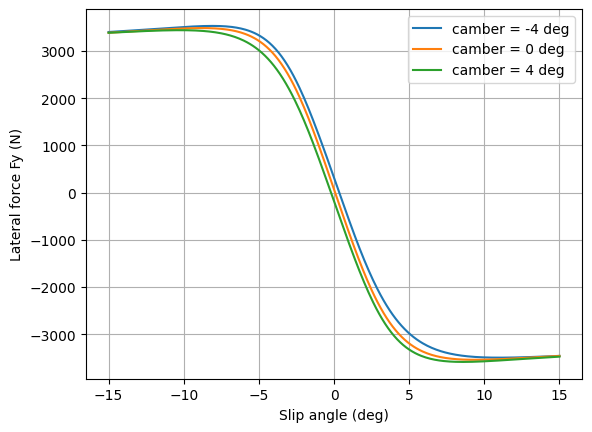

In [10]:
for cam_deg in [-4, 0, 4]:
    cam = np.radians(cam_deg)
    plt.plot(alpha_deg, lateral_force(alpha, 4000, cam), label=f"camber = {cam_deg} deg")
    print(cam_deg, lateral_force(0.0, 4000, cam))

plt.xlabel("Slip angle (deg)")
plt.ylabel("Lateral force Fy (N)")
plt.legend()
plt.grid(True)
plt.show()

2000 1.083592007745697
4000 1.042208639149136
6000 1.0008307440049309
8000 0.9594762599909544


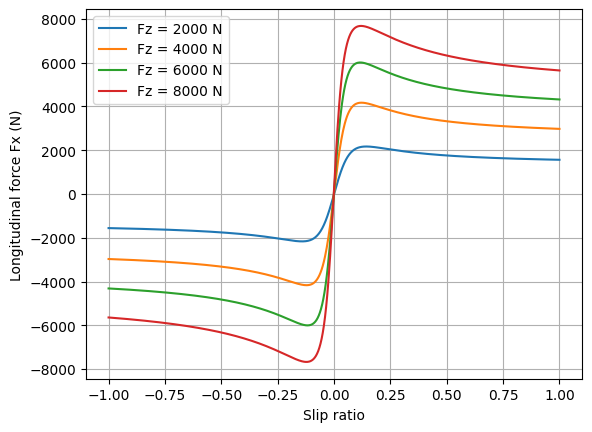

In [11]:
lon = tyre["LONGITUDINAL_COEFFICIENTS"]

def longitudinal_force(kappa, Fz):
    dfz = (Fz - Fz0) / Fz0

    # peak
    Cx = lon["PCX1"]
    mu_x = lon["PDX1"] + lon["PDX2"] * dfz
    Dx = mu_x * Fz

    # stiffness
    Kxk = Fz * (lon["PKX1"] + lon["PKX2"] * dfz) * np.exp(lon["PKX3"] * dfz)
    Bx = Kxk / (Cx * Dx)

    # shifts
    SHx = lon["PHX1"] + lon["PHX2"] * dfz
    SVx = Fz * (lon["PVX1"] + lon["PVX2"] * dfz)

    # shifted slip and curvature
    kappa_x = kappa + SHx
    Ex = ((lon["PEX1"] + lon["PEX2"] * dfz + lon["PEX3"] * dfz**2)
          * (1 - lon["PEX4"] * np.sign(kappa_x)))
    Ex = np.minimum(Ex, 1.0)

    return magic_formula(kappa_x, Bx, Cx, Dx, Ex) + SVx


kappa = np.linspace(-1, 1, 801)

for Fz in [2000, 4000, 6000, 8000]:
    plt.plot(kappa, longitudinal_force(kappa, Fz), label=f"Fz = {Fz} N")
    print(Fz, longitudinal_force(kappa, Fz).max() / Fz)

plt.xlabel("Slip ratio")
plt.ylabel("Longitudinal force Fx (N)")
plt.legend()
plt.grid(True)
plt.show()

In [21]:
def weight(x, B, C, E, SH):
    def g(s):
        Bs = B * s
        return np.cos(C * np.arctan(Bs - E * (Bs - np.arctan(Bs))))
    return g(x + SH) / g(SH)


def combined_force(kappa, alpha, Fz, gamma=0.0):
    dfz = (Fz - Fz0) / Fz0

    Fx0 = longitudinal_force(kappa, Fz)
    Fy0 = lateral_force(alpha, Fz, gamma)

    # Fx is reduced by slip angle
    Bxa = lon["RBX1"] * np.cos(np.arctan(lon["RBX2"] * kappa))
    Exa = min(lon["REX1"] + lon["REX2"] * dfz, 1.0)
    Gx = weight(alpha, Bxa, lon["RCX1"], Exa, lon["RHX1"])

    # Fy is reduced by slip ratio
    Byk = lat["RBY1"] * np.cos(np.arctan(lat["RBY2"] * (alpha - lat["RBY3"])))
    Eyk = min(lat["REY1"] + lat["REY2"] * dfz, 1.0)
    SHyk = lat["RHY1"] + lat["RHY2"] * dfz
    Gy = weight(kappa, Byk, lat["RCY1"], Eyk, SHyk)
    
    
    # side force induced by braking or driving
    mu_y = lat["PDY1"] + lat["PDY2"] * dfz
    DVyk = (mu_y * Fz * (lat["RVY1"] + lat["RVY2"] * dfz + lat["RVY3"] * np.sin(gamma))
            * np.cos(np.arctan(lat["RVY4"] * alpha)))
    SVyk = DVyk * np.sin(lat["RVY5"] * np.arctan(lat["RVY6"] * kappa))
    
    
    return Gx * Fx0, Gy * Fy0 + induced_side_force(kappa, alpha, Fz, gamma)


print(combined_force(-0.12, np.radians(4), 4000))
print(combined_force(-0.05, 0.0, 4000))

(np.float64(-3547.5703623475592), np.float64(-2008.0377062101948))
(np.float64(-3284.832084873775), np.float64(-117.62668428249617))


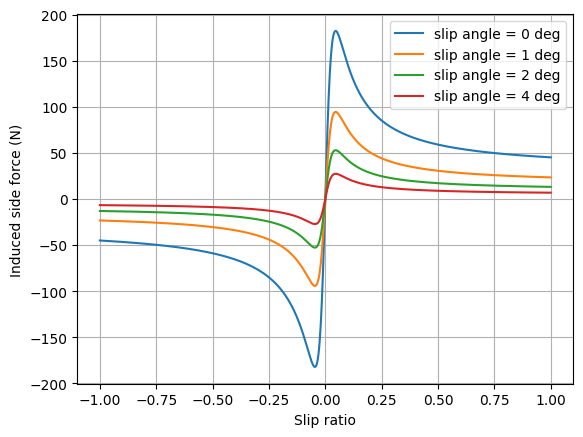

In [22]:
kappa = np.linspace(-1, 1, 801)

for a_deg in [0, 1, 2, 4]:
    plt.plot(kappa, induced_side_force(kappa, np.radians(a_deg), 4000),
             label=f"slip angle = {a_deg} deg")

plt.xlabel("Slip ratio")
plt.ylabel("Induced side force (N)")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
def induced_side_force(kappa, alpha, Fz, gamma=0.0):
    dfz = (Fz - Fz0) / Fz0
    mu_y = lat["PDY1"] + lat["PDY2"] * dfz
    DVyk = (mu_y * Fz * (lat["RVY1"] + lat["RVY2"] * dfz + lat["RVY3"] * np.sin(gamma))
            * np.cos(np.arctan(lat["RVY4"] * alpha)))
    return DVyk * np.sin(lat["RVY5"] * np.arctan(lat["RVY6"] * kappa))

In [23]:
ali = tyre["ALIGNING_COEFFICIENTS"]
R0 = tyre["DIMENSION"]["UNLOADED_RADIUS"]

def aligning_moment(alpha, Fz):
    dfz = (Fz - Fz0) / Fz0

    # lateral quantities, as in lateral_force at zero camber
    Kya = lat["PKY1"] * Fz0 * np.sin(lat["PKY4"] * np.arctan(Fz / (lat["PKY2"] * Fz0)))
    SHy = lat["PHY1"] + lat["PHY2"] * dfz
    SVy = Fz * (lat["PVY1"] + lat["PVY2"] * dfz)
    Fy0 = lateral_force(alpha, Fz)

    # pneumatic trail
    alpha_t = alpha + ali["QHZ1"] + ali["QHZ2"] * dfz
    Bt = ali["QBZ1"] + ali["QBZ2"] * dfz + ali["QBZ3"] * dfz**2
    Ct = ali["QCZ1"]
    Dt = Fz * (R0 / Fz0) * (ali["QDZ1"] + ali["QDZ2"] * dfz)
    Et = ((ali["QEZ1"] + ali["QEZ2"] * dfz + ali["QEZ3"] * dfz**2)
          * (1 + ali["QEZ4"] * (2 / np.pi) * np.arctan(Bt * Ct * alpha_t)))
    Et = np.minimum(Et, 1.0)
    Bat = Bt * alpha_t
    trail = Dt * np.cos(Ct * np.arctan(Bat - Et * (Bat - np.arctan(Bat)))) * np.cos(alpha)

    # residual torque
    alpha_r = alpha + SHy + SVy / Kya
    Dr = Fz * R0 * (ali["QDZ6"] + ali["QDZ7"] * dfz) * np.cos(alpha)
    Mzr = Dr * np.cos(np.arctan(ali["QBZ9"] * alpha_r))

    return -trail * Fy0 + Mzr, trail


print(aligning_moment(np.radians(3), 4000))

(np.float64(44.77646744415811), np.float64(0.018353322016269786))


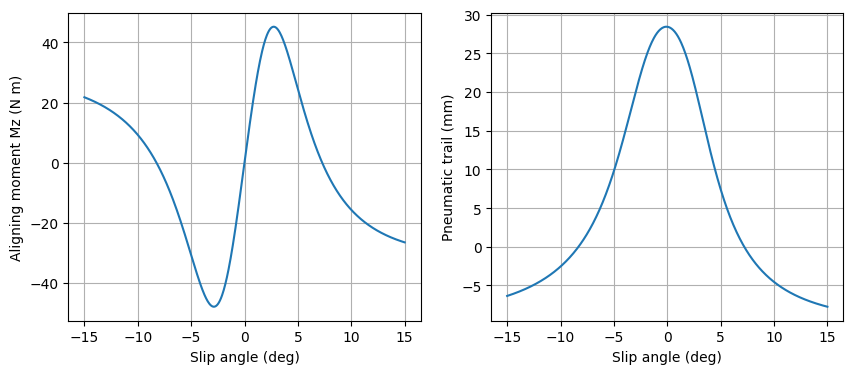

In [24]:
alpha_deg = np.linspace(-15, 15, 601)
alpha = np.radians(alpha_deg)
Mz, trail = aligning_moment(alpha, 4000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(alpha_deg, Mz)
ax1.set_xlabel("Slip angle (deg)")
ax1.set_ylabel("Aligning moment Mz (N m)")
ax1.grid(True)
ax2.plot(alpha_deg, trail * 1000)
ax2.set_xlabel("Slip angle (deg)")
ax2.set_ylabel("Pneumatic trail (mm)")
ax2.grid(True)
plt.show()